# Project 5: Uganda Tax Engine
**OOP with Python Assignment 2**  
**Programme:** MSc Data Science and Analytics

I developed a Python tax calculator using OOP to calculate PAYE, NSSF, LST, VAT and corporate income tax. I also included a `TaxPlanner` to compare take home pay. The project uses Uganda's 2026 PAYE rates and is for learning purposes only. I named it **Project 5** to follow my earlier projects.


## 1. Getting the Notebook Ready

I imported the required libraries and classes from `src/tax_engine.py`. I also checked the project folder to avoid import errors and used `Decimal` for accurate tax calculations.

In [10]:
from pathlib import Path
import sys

# I run the notebook from the main project folder so Python can find my classes.
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "tax_engine.py").is_file():
    raise FileNotFoundError(
        "Project root not found. Open a terminal in the folder containing "
        "project5_uganda_tax_engine.ipynb and run: jupyter notebook"
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
from decimal import Decimal
import pandas as pd
import matplotlib.pyplot as plt
from src.tax_engine import (
    Money, ugx, Tax, TaxContext, PAYETax, Payroll,
    VATTax, Invoice, CorporateIncomeTax, TaxPlanner,
    InvalidIncomeError, NoScheduleForDateError
)
print("Loaded Uganda Tax Engine from:", ROOT)


Loaded Uganda Tax Engine from: D:\MSDS\OOP\Assignment 2 mini project\Project_5_Uganda_Tax_Engine_Clean


## 2. How I Used Object-Oriented Programming

I used a `Money` class to handle UGX amounts and an abstract `Tax` class for PAYE, VAT and corporate income tax. I applied inheritance and polymorphism in tax calculations, while composition was used in `Payroll` and `TaxPlanner` to reuse calculations.

In [11]:
a, b = ugx('1000.50'), ugx(500)
print('Money rounded:', a, '| sum:', a + b, '| multiplied:', b * Decimal('0.05'))
print('Subclass of Tax:', issubclass(PAYETax, Tax), issubclass(VATTax, Tax), issubclass(CorporateIncomeTax, Tax))

Money rounded: UGX 1,001 | sum: UGX 1,501 | multiplied: UGX 25
Subclass of Tax: True True True


## 3. Calculating PAYE for residents and non-residents

Here I check how the PAYE calculator handles different monthly income levels. I included amounts at the edges of the tax bands because that is where calculation mistakes are easy to miss.

For a resident employee, the first UGX 335,000 is not taxed. Income above that is taxed using the next bands: 20% up to UGX 410,000, then 25% up to UGX 485,000 and 30% above that. The assignment also requires an additional 10% on the amount exceeding UGX 10 million.

Non-residents follow a different schedule, beginning with 10% on income up to UGX 335,000. I calculate both so that I can compare the results at the same income levels. The program rounds the final tax amounts to whole shillings.


In [12]:
paye = PAYETax()
levels = [0, 335000, 335001, 410000, 410001, 485000, 485001, 1000000, 10000000, 10000001, 11000000]
rows = []
for income in levels:
    for residency in ('resident', 'nonresident'):
        result = paye.calculate(TaxContext(ugx(income), on_date=date(2026,10,1), residency=residency))
        rows.append({'Monthly taxable income (UGX)': income, 'Residency': residency, 'PAYE (UGX)': int(result.tax.amount)})
paye_df = pd.DataFrame(rows)
print(paye_df.to_string(index=False))

 Monthly taxable income (UGX)   Residency  PAYE (UGX)
                            0    resident           0
                            0 nonresident           0
                       335000    resident           0
                       335000 nonresident       33500
                       335001    resident           0
                       335001 nonresident       33500
                       410000    resident       15000
                       410000 nonresident       48500
                       410001    resident       15000
                       410001 nonresident       48500
                       485000    resident       33750
                       485000 nonresident       71000
                       485001    resident       33750
                       485001 nonresident       71000
                      1000000    resident      188250
                      1000000 nonresident      225500
                     10000000    resident     2888250
                     1000000

## 4. Comparing PAYE on a Graph

I plotted PAYE against monthly income to compare tax amounts for residents and non-residents. I used `Decimal` for calculations and converted the results to integers for plotting.

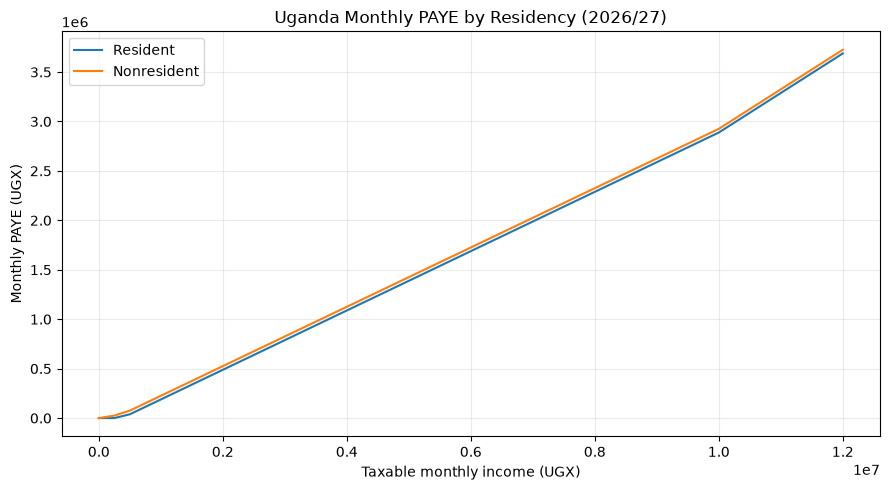

In [13]:
incomes = list(range(0, 12000001, 250000))
fig, ax = plt.subplots(figsize=(9,5))
for residency in ('resident','nonresident'):
    taxes = [int(paye.calculate(TaxContext(ugx(x), residency=residency)).tax.amount) for x in incomes]
    ax.plot(incomes, taxes, label=residency.title())
ax.set(title='Uganda Monthly PAYE by Residency (2026/27)', xlabel='Taxable monthly income (UGX)', ylabel='Monthly PAYE (UGX)')
ax.legend(); ax.grid(alpha=.25); fig.tight_layout(); plt.show()

## 5. Working Out Payroll Deductions

I calculated gross pay by adding salary and taxable allowances. I then applied NSSF at 5% for employees and 10% for employers. I deducted LST before calculating PAYE and worked out net pay after employee deductions. Employer NSSF was treated separately, while employee NSSF was not deducted from taxable income.

In [14]:
payroll = Payroll()
case = payroll.calculate(basic=ugx(1000000), allowances=ugx(150000), lst=ugx(10000), residency='resident')
for label, value in vars(case).items():
    print(f'{label:23s}: {value}')

gross                  : UGX 1,150,000
employee_nssf          : UGX 57,500
employer_nssf          : UGX 115,000
local_service_tax      : UGX 10,000
paye_base              : UGX 1,140,000
paye                   : UGX 230,250
net_pay                : UGX 852,250
employer_total_cost    : UGX 1,265,000


## 6. Calculating VAT

I calculated VAT using sample sales and purchase invoices. I applied 18% to standard-rated supplies and treated zero-rated and exempt supplies separately. I also included eligible input VAT. The calculations are simplified and do not cover all VAT adjustments.

In [15]:
invoices = [
    Invoice('SALE-01','sale','standard',ugx(1000000)),
    Invoice('SALE-02','sale','zero',ugx(300000)),
    Invoice('SALE-03','sale','exempt',ugx(200000)),
    Invoice('BUY-01','purchase','standard',ugx(250000)),
    Invoice('BUY-02','purchase','exempt',ugx(50000)),
]
vat = VATTax().invoices(invoices)
print(pd.DataFrame([{'Reference':i.reference,'Direction':i.direction,'Supply':i.category,'Net UGX':int(i.net_amount.amount)} for i in invoices]).to_string(index=False))
print('Output VAT:',vat.output_vat,'| Eligible input VAT:',vat.input_vat,'| VAT payable:',vat.vat_payable,'| Credit:',vat.credit_balance)

Reference Direction   Supply  Net UGX
  SALE-01      sale standard  1000000
  SALE-02      sale     zero   300000
  SALE-03      sale   exempt   200000
   BUY-01  purchase standard   250000
   BUY-02  purchase   exempt    50000
Output VAT: UGX 180,000 | Eligible input VAT: UGX 45,000 | VAT payable: UGX 135,000 | Credit: UGX 0


## 7. Calculating Corporate Income Tax

I calculated corporate income tax by subtracting allowable deductions from business revenue and applying a 30% tax rate. I ensured that the tax cannot be negative. The calculation excludes special tax rules and incentives.

In [16]:
corporate = CorporateIncomeTax().from_accounts(revenue=ugx(120000000), allowable_deductions=ugx(75000000))
print('Chargeable income:', corporate.taxable_base)
print('Corporate income tax:', corporate.tax)

Chargeable income: UGX 45,000,000
Corporate income tax: UGX 13,500,000


## 8. Comparing Two Payroll Scenarios with TaxPlanner

I used `TaxPlanner` to compare net pay under two different salary and allowance scenarios. I calculated the take-home pay for each and found the difference using the same payroll rules.

In [17]:
comparison = TaxPlanner().compare(
    {'basic':ugx(1000000),'allowances':ugx(0),'lst':ugx(0)},
    {'basic':ugx(1200000),'allowances':ugx(100000),'lst':ugx(0)}
)
print('Scenario A net:', comparison.first.net_pay)
print('Scenario B net:', comparison.second.net_pay)
print('B minus A:', comparison.net_pay_difference)

Scenario A net: UGX 761,750
Scenario B net: UGX 956,750
B minus A: UGX 195,000


## 9. Checking Errors and Testing the Calculations

I added checks for invalid income and dates outside the PAYE period. I also used tests, including Hypothesis, to check tax band limits and ensure that tax is not negative, does not decrease as income increases and does not exceed taxable income.

In [18]:
for label, operation in [
    ('Negative income', lambda: paye.calculate(TaxContext(ugx(-100)))),
    ('Unsupported date', lambda: paye.calculate(TaxContext(ugx(500000), on_date=date(2025,1,1)))),
    ('Float money input', lambda: ugx(0.1))
]:
    try:
        operation()
    except (InvalidIncomeError, NoScheduleForDateError) as exc:
        print(f'{label}: correctly rejected — {type(exc).__name__}: {exc}')
    else:
        raise AssertionError(f'{label} should have failed')

assert paye.calculate(TaxContext(ugx(335000))).tax == ugx(0)
assert paye.calculate(TaxContext(ugx(410000))).tax == ugx(15000)
assert paye.calculate(TaxContext(ugx(485000))).tax == ugx(33750)
assert paye.calculate(TaxContext(ugx(335000), residency='nonresident')).tax == ugx(33500)
assert vat.vat_payable == ugx(135000)
print('Five offline notebook assertions passed.')

Negative income: correctly rejected — InvalidIncomeError: Taxable amount cannot be negative.
Unsupported date: correctly rejected — NoScheduleForDateError: PAYE schedule configured only from 2026-07-01.
Float money input: correctly rejected — InvalidIncomeError: Use int, str or Decimal; float is prohibited.
Five offline notebook assertions passed.


## 10. What I Learnt and the Limits of the Project

I used `Decimal` to avoid rounding errors in tax calculations. I applied inheritance to PAYE, VAT and corporate income tax, while composition was used for `Payroll` and `TaxPlanner`.

The project uses PAYE rates from 1 July 2026 and simplified VAT and corporate tax rules. I referred to URA guidance and the assignment requirements.

I also used AI assistance in developing the project. The calculations can be tested, but the program is for learning purposes, not actual tax filing.